# 02 · Modelos abiertos, aprendizaje por transferencia y ajuste fino

Este es un módulo de Neural Networks 1002 y supone los módulos 01 a 03, 05, 09 y 10 de [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/) (neurona, retropropagación, entrenar bien, CNN, transformer, GPT desde cero).

Casi nadie entrena ya una red seria desde cero. El punto de partida habitual es un **checkpoint** (un archivo de pesos entrenados) que alguien publicó: una red de imágenes entrenada con ImageNet, un codificador de texto entrenado con un corpus grande, un modelo de lenguaje entrenado con billones de palabras. Este notebook trata de usar bien esos checkpoints:

* **qué significa realmente "abierto"** para un modelo, qué licencias existen y por qué hay que leer la licencia de un checkpoint *antes* de construir un producto sobre él;
* cómo **cargar modelos preentrenados reales** en un portátil, y qué cuestan y qué aportan el tamaño, la precisión numérica y la cuantización (guardar los pesos con menos bits);
* el **aprendizaje por transferencia** medido con rigor: una sonda lineal sobre características congeladas, el ajuste fino de solo las últimas capas y el ajuste fino completo, en una tarea de imágenes y una de texto, con la exactitud en función del número de ejemplos etiquetados y del número de parámetros entrenables;
* el **ajuste fino eficiente en parámetros**: LoRA (low-rank adaptation, adaptación de bajo rango) escrito desde cero y luego con la biblioteca `peft`; adaptadores, QLoRA y destilación explicados;
* **guardar, cargar y exportar**: `state_dict` frente a pickle del modelo entero (y por qué pickle no es seguro), safetensors, checkpoints que reanudan el entrenamiento, exportación a ONNX (Open Neural Network Exchange) comprobada con ONNX Runtime, y una tarjeta del modelo;
* una **guía de decisión** y una lista de comprobación de licencias y seguridad.

Contenido:

1. Qué significa "abierto": código abierto, pesos abiertos, datos abiertos y las licencias
2. Hubs y modelos preentrenados reales en CPU: tamaño, precisión y cuantización
3. Aprendizaje por transferencia, medido: tarea de imágenes (ResNet-18) y tarea de texto (un BERT pequeño)
4. Ajuste fino eficiente en parámetros: LoRA desde cero y con `peft`, adaptadores, QLoRA, destilación
5. Guardar, cargar y exportar modelos
6. Una guía de decisión y una lista de comprobación
7. Ideas clave, ejercicios y referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| módulos 01 y 02 de [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/): la neurona y la retropropagación | una matriz de pesos, gradientes, lo que desactiva `requires_grad` |
| módulo 03 de [1001](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/): entrenar bien | particiones entrenamiento/prueba, tasas de aprendizaje, sobreajuste con pocos ejemplos |
| módulo 05 de [1001](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/): CNN | los primeros experimentos de transferencia (ResNet congelada frente a ajustada); aquí los medimos frente al número de etiquetas en lugar de repetirlos |
| módulos 09 y 10 de [1001](https://neural-networks.academy.forwardforecasting.eu/es/): el transformer y los LLM (GPT desde cero) | capas de atención cuyas proyecciones `q` y `v` adaptaremos con LoRA |
| módulo 01 de [Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/01-rlhf-y-alineacion/): RLHF y alineamiento | por qué un checkpoint base es solo el primer paso |
| módulo 12 de [1001](https://neural-networks.academy.forwardforecasting.eu/es/12-proyecto-final-caso-real/): proyecto final de inspección de defectos | transferencia con fotos reales de piezas fabricadas, con la misma red de ImageNet |

Este módulo **no** repite lo básico de PyTorch, TensorFlow ni de la carga con Hugging Face; el curso Python 1001 lo cubre en [AI frameworks](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/). Aquí suponemos que ya sabes ejecutar `AutoModel.from_pretrained(...)` y preguntamos qué hay detrás.

**En qué se diferencia el juguete de los sistemas reales.** Las tareas son pequeñas a propósito (una tarea de ropa de 10 clases con imágenes de 48x48 píxeles y una tarea de 8 intenciones con como máximo 160 frases etiquetadas) y el modelo de texto es un BERT de 11 M de parámetros, no un modelo de lenguaje de miles de millones. Los números muestran la *forma* de los compromisos, no lo que obtendrías con un modelo de producción y datos reales.

La primera vez necesita unas pocas descargas pequeñas (unos 45 MB para ResNet-18, 17 MB para el modelo de texto, 270 MB para DistilBERT, unos MB de datos); todas se guardan en caché, así que las siguientes ejecuciones empiezan enseguida. Todo el notebook se ejecutó en unos 4 minutos en un entorno limpio de 2 CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/02_modelos_abiertos_y_ajuste_fino.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 4 minutos, con un pico de memoria de unos 2,6 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'onnx': 'onnx',
    'onnxruntime': 'onnxruntime',
    'pandas': 'pandas',
    'peft': 'peft',
    'safetensors': 'safetensors',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
    'onnxscript': 'onnxscript',
    'accelerate': 'accelerate',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings, logging, os
warnings.filterwarnings("ignore")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import io, time, copy, math, json, pickle, tempfile, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
T_START = time.time()
def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))
def size_mb(obj):
    buf = io.BytesIO(); torch.save(obj, buf); return buf.tell() / 1e6

## 1. Qué significa "abierto"

"Modelo abierto" se usa con vaguedad. Pueden ser abiertas tres cosas distintas, y una publicación puede tener cualquier combinación:

| Término | Qué se publica | Qué puedes hacer | Ejemplo de uso |
|---|---|---|---|
| **código abierto** (sentido estricto) | código con una licencia [aprobada por la OSI](https://opensource.org/licenses) (usar, estudiar, modificar, compartir, para cualquier fin) | todo lo que lista la licencia | el código de PyTorch o de Transformers |
| **pesos abiertos** | los parámetros entrenados (el checkpoint), normalmente con una licencia que puede restringir el uso | ejecutarlo, ajustarlo, a menudo redistribuirlo, dentro de la licencia | Llama, Gemma, la mayoría de los checkpoints del Hugging Face Hub |
| **datos abiertos** | los datos de entrenamiento y una descripción de cómo se recogieron y filtraron | auditarlos, reproducir el entrenamiento, comprobar fugas y sesgos | pocos modelos, porque los datos suelen tener límites de derechos de autor y privacidad |

La **Open Source AI Definition 1.0 de la Open Source Initiative** ([OSAID 1.0](https://opensource.org/ai/open-source-ai-definition), octubre de 2024) dice que, para contar como código abierto, un sistema de IA debe darte las cuatro libertades (usar, estudiar, modificar, compartir) y la *forma preferida para hacer modificaciones*: los pesos, el código para entrenarlo y ejecutarlo, e **información suficientemente detallada sobre los datos** de entrenamiento. Muchos modelos "abiertos" populares publican solo los pesos y, según esta definición, son de *pesos abiertos*, no de código abierto. No es un juicio de calidad; indica en qué puedes apoyarte.

### Licencias que encontrarás

| Licencia | Uso típico | Qué te permite | Ten cuidado con |
|---|---|---|---|
| [Apache 2.0](https://www.apache.org/licenses/LICENSE-2.0) | DistilBERT, BERT, muchos modelos pequeños y el código de la mayoría de las bibliotecas | usar, modificar y redistribuir, también comercialmente; incluye una concesión de patentes | conservar el aviso e indicar tus cambios |
| [MIT](https://opensource.org/license/mit) | muchos modelos de investigación y conjuntos de datos, por ejemplo Fashion-MNIST | casi todo, también comercialmente | conservar el aviso de copyright; sin garantía |
| [OpenRAIL](https://huggingface.co/blog/open_rail) (por ejemplo [BigScience RAIL para BLOOM](https://huggingface.co/spaces/bigscience/license)) | modelos publicados con restricciones de comportamiento | usar y modificar, también comercialmente, **pero** no puedes usarlo para los fines dañinos listados y debes trasladar esas restricciones | no es una licencia de la OSI: las restricciones de uso forman parte de la licencia |
| [Licencia comunitaria de Llama](https://www.llama.com/llama3/license/) | la familia Llama de Meta | usar y ajustar, también comercialmente, por debajo de un umbral de usuarios | los servicios muy grandes necesitan otra licencia; se aplica una política de uso aceptable; reglas de nombre para modelos derivados |
| [Términos de uso de Gemma](https://ai.google.dev/gemma/terms) | la familia Gemma de Google | usar y ajustar, también comercialmente, con una política de usos prohibidos | los términos deben trasladarse a quienes se lo distribuyas; no son una licencia de la OSI |
| [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) | muchos conjuntos de datos, por ejemplo el del proyecto final (módulo 12 de Neural Networks 1001) | reutilizar con atribución | citar la fuente |

Estos resúmenes son orientación, no asesoramiento jurídico: lee el texto de la licencia de la que dependes, porque los detalles (umbrales, reglas de nombre, límites de campo de uso, quién queda obligado) difieren y cambian entre versiones.

### Tarjetas de modelo y de datos

Una **tarjeta de modelo** (Mitchell et al., [2019](https://arxiv.org/abs/1810.03993)) es un documento breve que acompaña a un checkpoint: para qué sirve y para qué no, con qué datos se entrenó, cómo se evaluó (y en qué grupos), límites y sesgos conocidos. Una **tarjeta de datos** hace lo mismo con los datos ([guía de Hugging Face sobre tarjetas de datos](https://huggingface.co/docs/hub/datasets-cards), [tarjetas de modelo](https://huggingface.co/docs/hub/model-cards)). En el Hub son el `README.md` del repositorio, con una cabecera de metadatos (licencia, idioma, modelo base, datos) que las herramientas pueden leer.

### Por qué importa la licencia antes de construir

Un modelo ajustado **hereda las obligaciones** del checkpoint y de los datos de los que viene. Descubrir tras seis meses de trabajo que tu modelo base prohíbe el uso comercial, que tus datos de entrenamiento eran solo no comerciales, o que una restricción debe trasladarse a tus clientes, sale caro. La siguiente celda lee el campo de licencia de los checkpoints y conjuntos de datos de este notebook directamente de los metadatos del Hub, que es como comprobarías a un candidato en la práctica (y algunos ejemplos conocidos para comparar).

In [2]:
from huggingface_hub import HfApi
api = HfApi()
rows = []
models = ["distilbert/distilbert-base-uncased", "google/bert_uncased_L-4_H-256_A-4", "HuggingFaceTB/SmolLM2-135M",
          "mistralai/Mistral-7B-v0.1", "google/gemma-2-2b", "meta-llama/Llama-3.2-1B", "bigscience/bloom"]
datasets_ = ["PolyAI/banking77", "zalando-datasets/fashion_mnist"]
for kind, ids in [("model", models), ("dataset", datasets_)]:
    for i in ids:
        try:
            info = api.model_info(i) if kind == "model" else api.dataset_info(i)
            lic = info.card_data.license if info.card_data is not None else None
            lic = ", ".join(lic) if isinstance(lic, list) else lic
            gated = bool(getattr(info, "gated", False))
        except Exception as e:
            lic, gated = "(no se pudo contactar con el Hub)", False
        rows.append((kind, i, lic, "sí" if gated else "no"))
print(pd.DataFrame(rows, columns=["tipo", "repositorio", "campo de licencia", "acceso restringido (con aceptación)"]).to_string(index=False))

   tipo                        repositorio         campo de licencia acceso restringido (con aceptación)
  model distilbert/distilbert-base-uncased                apache-2.0                                  no
  model  google/bert_uncased_L-4_H-256_A-4                apache-2.0                                  no
  model         HuggingFaceTB/SmolLM2-135M                apache-2.0                                  no
  model          mistralai/Mistral-7B-v0.1                apache-2.0                                  no
  model                  google/gemma-2-2b                     gemma                                  sí
  model            meta-llama/Llama-3.2-1B                  llama3.2                                  sí
  model                   bigscience/bloom bigscience-bloom-rail-1.0                                  no
dataset                   PolyAI/banking77                 cc-by-4.0                                  no
dataset     zalando-datasets/fashion_mnist             

**Lectura.** Los codificadores pequeños (DistilBERT, BERT-Mini, SmolLM2) y Mistral 7B llevan Apache 2.0 sin más; Gemma y Llama llevan sus propios identificadores de licencia (`gemma`, `llama3.2`) y están *restringidos*: hay que aceptar sus términos en el Hub antes de descargarlos, lo que ya es señal de que la licencia tiene condiciones que leer; BLOOM lleva una licencia OpenRAIL. Los dos conjuntos de datos son CC BY 4.0 y MIT. Fíjate en lo que esta celda no puede decirte: el campo de metadatos es una etiqueta, no el texto de la licencia, y no dice nada de las licencias de los datos con que se entrenó el modelo. Abre el archivo de licencia antes de depender de él.

## 2. Hubs y modelos preentrenados reales en CPU

Un **hub** es un registro donde se publican y versionan checkpoints, conjuntos de datos y sus tarjetas; el Hugging Face Hub es el mayor, y `torchvision`, TensorFlow Hub y el ONNX Model Zoo cumplen papeles parecidos para familias más estrechas. Cargar es una línea, y el archivo se guarda en disco la primera vez. Aquí cargamos [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased) (Sanh et al., [2019](https://arxiv.org/abs/1910.01108); licencia Apache 2.0), un BERT comprimido, y miramos lo que realmente hemos descargado: cuántos parámetros, cuántos bytes y qué cuesta cada precisión.

### Tamaño, precisión y cuantización

Un peso es un número, y los números pueden guardarse con distinto número de bits:

| Formato | Bytes por peso | Notas |
|---|---|---|
| float32 (fp32) | 4 | el valor por defecto para entrenar |
| bfloat16 / float16 | 2 | reduce la memoria a la mitad; entrenamiento e inferencia en GPU y CPU recientes |
| int8 | 1 | **cuantización**: pesos guardados como enteros de 8 bits más una escala; los productos de matrices se hacen en aritmética entera |
| 4 bits | 0,5 | lo usan las herramientas para modelos grandes (y QLoRA, sección 4); necesita núcleos especiales |

La **cuantización dinámica** (`torch.ao.quantization.quantize_dynamic`) convierte una sola vez los pesos de las capas `nn.Linear` a int8 y cuantiza las activaciones sobre la marcha en cada llamada. No necesita datos ni entrenamiento, por eso es lo primero que se prueba para inferencia en CPU. Medimos las tres cosas que importan: tamaño en disco, velocidad y si las salidas siguen coincidiendo con las originales.

In [3]:
from transformers import AutoTokenizer, AutoModel
t0 = time.time()
tok_d = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
distil = AutoModel.from_pretrained("distilbert/distilbert-base-uncased").eval()
print(f"DistilBERT cargado en {time.time() - t0:.1f} s, {count_params(distil) / 1e6:.1f} M de parámetros")

sentences = ["how do i top up my card", "my card payment was declined at the shop",
             "why was i charged a fee for a transfer", "i lost my phone, how do i freeze my account"] * 8   # 32 frases
batch = tok_d(sentences, return_tensors="pt", padding=True)

def pooled(model, b):
    with torch.no_grad():
        h = model(**b).last_hidden_state
    m = b["attention_mask"].unsqueeze(-1).to(h.dtype)
    return ((h * m).sum(1) / m.sum(1)).float()

def latency(model, b, reps=3):
    pooled(model, b)                       # calentamiento
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); pooled(model, b); ts.append(time.perf_counter() - t)
    return float(np.median(ts))

variants = {"fp32": distil,
            "bf16": copy.deepcopy(distil).to(torch.bfloat16),
            "int8 dynamic": torch.ao.quantization.quantize_dynamic(copy.deepcopy(distil), {nn.Linear}, dtype=torch.qint8)}
ref = pooled(distil, batch)
rows = []
for name, m in variants.items():
    out = pooled(m, batch)
    cos = F.cosine_similarity(out, ref, dim=1).mean().item()
    rows.append((name, size_mb(m.state_dict()), latency(m, batch) * 1000, cos))
q_table = pd.DataFrame(rows, columns=["precisión", "tamaño (MB)", "latencia, 32 frases (ms)", "similitud coseno con fp32"])
print(q_table.round(4).to_string(index=False))

DistilBERT cargado en 1.9 s, 66.4 M de parámetros


   precisión  tamaño (MB)  latencia, 32 frases (ms)  similitud coseno con fp32
        fp32     265.4880                  211.8182                     1.0000
        bf16     132.7622                  107.7661                     1.0000
int8 dynamic     138.1138                   83.7553                     0.9312


**Lectura.** La media precisión (bf16) reduce el archivo a la mitad (265 MB a 133 MB) y deja las salidas idénticas con cuatro decimales. El int8 dinámico lo reduce solo a 138 MB (52 %, no 25 %), porque la cuantización dinámica convierte solo las capas `nn.Linear` y la tabla de embeddings de palabras, de 23 M de parámetros, sigue en float32; los vectores de frase promediados se mueven de forma apreciable (similitud coseno de 0,931 con los de fp32), así que si eso importa depende de la tarea: la sección 4.5 lo mide en un clasificador. La velocidad es la parte que depende del hardware. En la CPU de servidor que produjo los números de arriba, bf16 fue 1,9 veces más rápido que fp32 (115 ms frente a 223 ms para 32 frases) e int8 2,7 veces (83 ms). En una CPU de portátil más antigua, sin aritmética bf16 rápida, medimos lo contrario para bf16: unas cuatro veces *más lento* que fp32, mientras que int8 seguía siendo 1,5 veces más rápido. Así que más pequeño no es automáticamente más rápido; mide en la máquina donde vayas a desplegar.

## 3. Aprendizaje por transferencia, medido

Aprendizaje por transferencia significa partir de pesos aprendidos en una tarea de origen grande y adaptarlos a una tarea de destino pequeña (Yosinski et al., [2014](https://arxiv.org/abs/1411.1792), midieron cuán generales son las características de cada capa; Howard y Ruder, [2018](https://arxiv.org/abs/1801.06146), mostraron la receta para texto con ULMFiT). Hay una escalera de opciones, de la más barata a la más cara:

| Estrategia | Qué se entrena | Parámetros entrenables | Riesgo |
|---|---|---|---|
| **sonda lineal** (extracción de características) | solo un clasificador lineal nuevo sobre características congeladas | diminutos | las características pueden no servir para la tarea nueva |
| **ajustar las últimas capas** | el bloque superior (o los bloques) y el clasificador | una fracción | hay que elegir cuántas capas |
| **ajuste fino completo** | todo | todos | sobreajusta conjuntos diminutos; necesita una tasa de aprendizaje pequeña; una copia completa por tarea |
| **entrenar desde cero** | todo, desde pesos aleatorios | todos | necesita muchos más datos (medimos cuántos) |

El módulo 05 de [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) mostró una vez características de ResNet congeladas y ajustadas, y el proyecto final (módulo 12 de 1001) las aplica a fotos reales. Aquí la pregunta es otra: **¿cómo se comparan las estrategias cuando el número de ejemplos etiquetados crece de un puñado a unos cientos, y cuánto cuesta cada una en parámetros entrenables?** Cada estrategia ve los *mismos* subconjuntos anidados de los datos de entrenamiento y el mismo conjunto de prueba. Semilla fija y una sola ejecución por celda, así que diferencias de dos o tres puntos están dentro del ruido (lo estimamos más abajo).

### 3.1 La tarea de imágenes: ResNet-18 de ImageNet con fotos de ropa

La red es la **ResNet-18** de `torchvision` (He et al., [2015](https://arxiv.org/abs/1512.03385)) con sus pesos `IMAGENET1K_V1` ([documentación](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)). El *código* de torchvision tiene licencia BSD-3; los *pesos* se entrenaron con ImageNet, cuyos [términos](https://www.image-net.org/download.php) limitan el uso a investigación y educación no comerciales: un buen ejemplo de checkpoint con una licencia más estricta que la biblioteca que lo sirve, algo que habría que resolver antes de lanzar un producto.

Los datos son **Fashion-MNIST** (Xiao et al., [2017](https://arxiv.org/abs/1708.07747); [tarjeta del conjunto](https://huggingface.co/datasets/zalando-datasets/fashion_mnist), licencia MIT): imágenes grises de 28x28 de diez clases de prendas. Las ampliamos a 48x48 y repetimos el canal tres veces. Es un *dominio deliberadamente distinto* de ImageNet (siluetas grises pequeñas, no fotos en color), así que la transferencia no es trivial. Los conjuntos de entrenamiento usan 2, 5, 10 y 30 imágenes por clase (20, 50, 100 y 300 en total), anidados de modo que cada uno es un prefijo del siguiente; el conjunto de prueba son 1000 imágenes fijas (100 por clase).

prueba: (1000, 3, 48, 48)  mayor conjunto de entrenamiento: (300, 3, 48, 48)


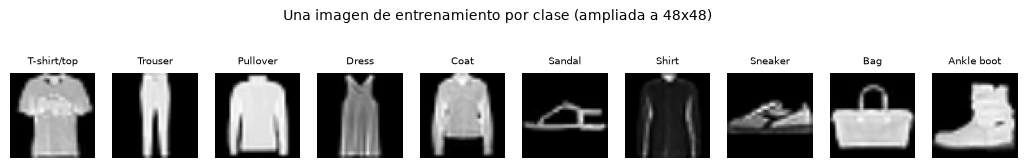

In [4]:
import torchvision
from huggingface_hub import hf_hub_download
from PIL import Image

FM_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def fm_split(split):
    p = hf_hub_download("zalando-datasets/fashion_mnist", f"fashion_mnist/{split}-00000-of-00001.parquet", repo_type="dataset")
    return pd.read_parquet(p)

df_tr, df_te = fm_split("train"), fm_split("test")
rng = np.random.default_rng(0)
IMG_SIZES = [2, 5, 10, 30]                       # imágenes por clase
order = {c: rng.permutation(np.where(df_tr.label.values == c)[0]) for c in range(10)}
test_idx = np.concatenate([rng.permutation(np.where(df_te.label.values == c)[0])[:100] for c in range(10)])
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_tensor(df, idx):
    x = np.stack([np.array(Image.open(io.BytesIO(df.image.iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255
    x = F.interpolate(torch.from_numpy(x).unsqueeze(1), size=48, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
    return (x - MEAN) / STD

def img_subset(k):
    idx = np.concatenate([order[c][:k] for c in range(10)])
    return to_tensor(df_tr, idx), torch.tensor(df_tr.label.values[idx])

Xte_img, yte_img = to_tensor(df_te, test_idx), torch.tensor(df_te.label.values[test_idx])
X30, y30 = img_subset(30)
print("prueba:", tuple(Xte_img.shape), " mayor conjunto de entrenamiento:", tuple(X30.shape))
fig, axes = plt.subplots(1, 10, figsize=(13, 1.7))
for c, ax in enumerate(axes):
    ax.imshow((X30[y30 == c][0, 0] * 0.226 + 0.449).numpy(), cmap="gray"); ax.set_title(FM_NAMES[c], fontsize=7); ax.axis("off")
plt.suptitle("Una imagen de entrenamiento por clase (ampliada a 48x48)", y=1.12, fontsize=10); plt.show()

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def make_resnet(pretrained):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(512, 10)
    return m

@torch.no_grad()
def evaluate(model, X, y, bs=250):
    model.eval()
    return float(np.mean(np.concatenate([model(X[i:i + bs]).argmax(1).numpy() == y[i:i + bs].numpy() for i in range(0, len(X), bs)])))

def features(model, X, bs=250):
    fc, model.fc = model.fc, nn.Identity()
    model.eval()
    with torch.no_grad():
        f = torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)]).numpy()
    model.fc = fc
    return f

def run_image(strategy, k, seed=0):
    # estrategias: probe (sonda), last (layer4 + fc), full (todo, preentrenado), scratch (todo, inicio aleatorio)
    torch.manual_seed(seed)
    X, y = img_subset(k)
    model = make_resnet(strategy != "scratch")
    t = time.time()
    if strategy == "probe":
        sc = StandardScaler().fit(features(model, X))
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(sc.transform(features(model, X)), y.numpy())
        acc = float((clf.predict(sc.transform(features(model, Xte_img))) == yte_img.numpy()).mean())
        return dict(strategy=strategy, k=k, n=len(X), trainable=512 * 10 + 10, acc=acc, seconds=time.time() - t, model=None)
    for p in model.parameters():
        p.requires_grad = strategy in ("full", "scratch")
    for p in model.fc.parameters():
        p.requires_grad = True
    if strategy == "last":
        for p in model.layer4.parameters():
            p.requires_grad = True
    backbone_lr = {"last": 2e-4, "full": 1e-4, "scratch": 1e-3}[strategy]
    groups = [{"params": model.fc.parameters(), "lr": 1e-3}]
    bb = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("fc.")]
    if bb:
        groups.append({"params": bb, "lr": backbone_lr})
    opt = torch.optim.Adam(groups)
    steps_per_epoch = math.ceil(len(X) / 32)
    epochs = max(4, math.ceil(30 / steps_per_epoch))
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train() if strategy in ("full", "scratch") else model.eval()      # estadísticas de BatchNorm congeladas salvo que se entrene todo
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 32):
            b = perm[i:i + 32]
            loss = F.cross_entropy(model(X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return dict(strategy=strategy, k=k, n=len(X), trainable=count_params(model, True), acc=evaluate(model, Xte_img, yte_img),
                seconds=time.time() - t, model=model if k == IMG_SIZES[-1] else None)

img_results = []
for strategy in ["probe", "last", "full", "scratch"]:
    for k in IMG_SIZES:
        r = run_image(strategy, k)
        img_results.append(r)
        print(f"{strategy:8s} {r['n']:4d} imágenes etiquetadas  entrenables {r['trainable']:>10,d}  exactitud en prueba {r['acc']:.3f}  ({r['seconds']:.0f} s)")
img_df = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in img_results])
IMG_MODELS = {r["strategy"]: r["model"] for r in img_results if r["model"] is not None}

probe      20 imágenes etiquetadas  entrenables      5,130  exactitud en prueba 0.551  (1 s)


probe      50 imágenes etiquetadas  entrenables      5,130  exactitud en prueba 0.687  (1 s)


probe     100 imágenes etiquetadas  entrenables      5,130  exactitud en prueba 0.721  (1 s)


probe     300 imágenes etiquetadas  entrenables      5,130  exactitud en prueba 0.762  (2 s)


last       20 imágenes etiquetadas  entrenables  8,398,858  exactitud en prueba 0.538  (3 s)


last       50 imágenes etiquetadas  entrenables  8,398,858  exactitud en prueba 0.697  (3 s)


... (6 outputs left out)

scratch    20 imágenes etiquetadas  entrenables 11,181,642  exactitud en prueba 0.478  (4 s)


scratch    50 imágenes etiquetadas  entrenables 11,181,642  exactitud en prueba 0.675  (5 s)


scratch   100 imágenes etiquetadas  entrenables 11,181,642  exactitud en prueba 0.689  (5 s)


scratch   300 imágenes etiquetadas  entrenables 11,181,642  exactitud en prueba 0.739  (7 s)


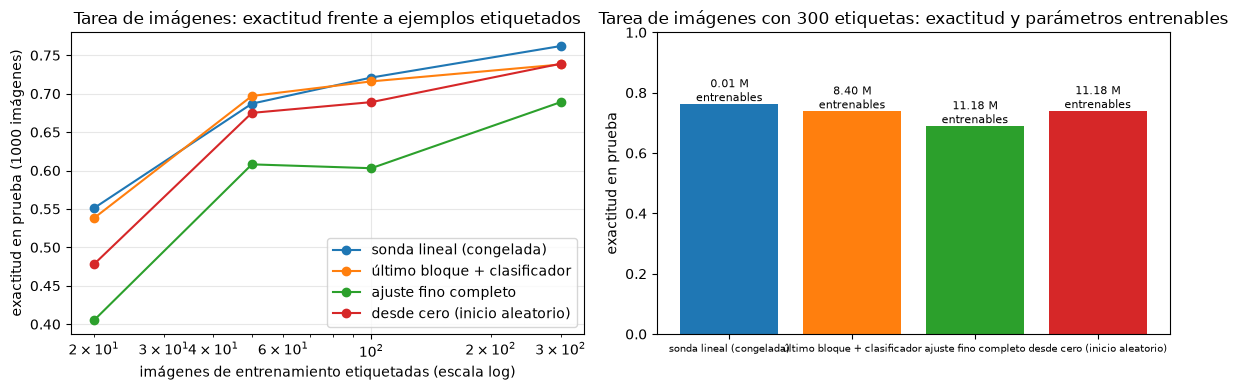

In [6]:
colors = {"probe": "tab:blue", "last": "tab:orange", "full": "tab:green", "scratch": "tab:red"}
labels = {"probe": "sonda lineal (congelada)", "last": "último bloque + clasificador", "full": "ajuste fino completo", "scratch": "desde cero (inicio aleatorio)"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s in colors:
    d = img_df[img_df.strategy == s]
    axes[0].plot(d.n, d.acc, "o-", color=colors[s], label=labels[s])
axes[0].set_xscale("log"); axes[0].set_xlabel("imágenes de entrenamiento etiquetadas (escala log)"); axes[0].set_ylabel("exactitud en prueba (1000 imágenes)")
axes[0].set_title("Tarea de imágenes: exactitud frente a ejemplos etiquetados"); axes[0].legend(); axes[0].grid(alpha=0.3)
d = img_df[img_df.n == 300]
axes[1].bar([labels[s] for s in d.strategy], d.acc, color=[colors[s] for s in d.strategy])
for i, (a, tr) in enumerate(zip(d.acc, d.trainable)):
    axes[1].text(i, a + 0.01, f"{tr / 1e6:.2f} M\nentrenables", ha="center", fontsize=8)
axes[1].set_ylim(0, 1.0); axes[1].set_ylabel("exactitud en prueba"); axes[1].set_title("Tarea de imágenes con 300 etiquetas: exactitud y parámetros entrenables")
axes[1].tick_params(axis="x", labelsize=7); plt.tight_layout(); plt.show()

**Lectura.** Exactitudes con 20, 50, 100 y 300 imágenes etiquetadas. Sonda lineal: 0,551, 0,687, 0,721, 0,762. Último bloque más clasificador: 0,538, 0,697, 0,716, 0,738. Ajuste fino completo: 0,405, 0,608, 0,603, 0,689. Desde cero: 0,478, 0,675, 0,689, 0,739. El conjunto de prueba tiene 1000 imágenes (un error estándar de unos 1,4 puntos) y cada celda es una ejecución con una semilla, así que con conjuntos de entrenamiento tan pequeños las diferencias de menos de 3 o 4 puntos no son fiables (las filas de ajuste completo y de desde cero también se movieron uno o dos puntos entre dos ejecuciones de este notebook, porque la aritmética con varios hilos no es reproducible bit a bit). Aun así hay tres cosas claras. Primero, la **sonda lineal, con solo 5.130 parámetros entrenables, es la mejor o está empatada con la mejor en todos los tamaños**, y además es con diferencia la más barata. Segundo, **el preentrenamiento ayudó solo con muy pocas etiquetas**: con 20 imágenes la sonda supera por 7 puntos al entrenamiento desde cero; con 50 la ventaja ya no existe (0,687 frente a 0,675, dentro del ruido). Tercero, **el ajuste fino completo fue la peor opción en todos los tamaños, y quedó por debajo del entrenamiento desde cero a partir de 50 imágenes**. Es un resultado negativo y no hay que interpretarlo en exceso: el dominio está lejos de ImageNet (siluetas grises de 48x48 frente a fotos en color), actualizamos los 11 M de pesos con muy pocos pasos y lotes de 32, y no afinamos ningún hiperparámetro. No contradice el módulo 12 de Neural Networks 1001, donde el ajuste fino ayudó con fotos reales; muestra que el ajuste fino no es gratis y hay que medirlo frente a la sonda. En qué se diferencia el juguete: 300 imágenes de 48x48 píxeles con una semilla, no un conjunto de datos real.

### 3.2 La tarea de texto: un codificador preentrenado pequeño con preguntas bancarias

Para texto usamos **BERT-Mini** (Turc et al., [2019](https://arxiv.org/abs/1908.08962); [página del modelo](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4), Apache 2.0): 4 capas transformer de ancho 256, 11 M de parámetros, lo bastante pequeño para ajustarlo en un portátil en segundos. Los datos son **Banking77** (Casanueva et al., [2020](https://arxiv.org/abs/2003.04807); [tarjeta del conjunto](https://huggingface.co/datasets/PolyAI/banking77), CC BY 4.0): preguntas cortas de clientes, cada una etiquetada con una de 77 intenciones. Nos quedamos con **8 intenciones** elegidas al azar con semilla fija y entrenamos con 2, 5, 10 y 20 frases por clase (16, 40, 80 y 160 frases etiquetadas); el conjunto de prueba son las 320 frases oficiales de prueba de esas 8 intenciones. El vector de frase es la media de la salida del codificador sobre los tokens, y el clasificador es una capa lineal encima, exactamente la misma estructura que en la tarea de imágenes.

In [7]:
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import DatasetCard

card = DatasetCard.load("PolyAI/banking77")
_nm = card.data.to_dict()["dataset_info"]["features"][1]["dtype"]["class_label"]["names"]
ALL_NAMES = [_nm[str(i)] for i in range(77)]
tr_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/train-00000-of-00001.parquet", repo_type="dataset"))
te_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/test-00000-of-00001.parquet", repo_type="dataset"))
rng = np.random.default_rng(1)
CLS = sorted(rng.choice(77, size=8, replace=False).tolist())
remap = {c: i for i, c in enumerate(CLS)}
TXT_NAMES = [ALL_NAMES[c] for c in CLS]
print("las 8 intenciones:", TXT_NAMES)
tr_b = tr_b[tr_b.label.isin(CLS)].reset_index(drop=True); te_b = te_b[te_b.label.isin(CLS)].reset_index(drop=True)
tr_b["y"] = tr_b.label.map(remap); te_b["y"] = te_b.label.map(remap)
TXT_SIZES = [2, 5, 10, 20]
order_t = {c: rng.permutation(np.where(tr_b.y.values == c)[0]) for c in range(8)}
def txt_subset(k):
    idx = np.concatenate([order_t[c][:k] for c in range(8)])
    return tr_b.text.values[idx].tolist(), torch.tensor(tr_b.y.values[idx])
te_text, te_y = te_b.text.tolist(), torch.tensor(te_b.y.values)
print(f"conjunto sin etiquetar: {len(tr_b)} frases de entrenamiento en total, prueba: {len(te_text)} frases")
print("ejemplo:", tr_b.text.iloc[0], "->", TXT_NAMES[tr_b.y.iloc[0]])

BERT = "google/bert_uncased_L-4_H-256_A-4"
tok = AutoTokenizer.from_pretrained(BERT)
def tokens(texts):
    return tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=32)

class TextClf(nn.Module):
    def __init__(self, encoder, n_classes=8):
        super().__init__()
        self.enc = encoder
        self.head = nn.Linear(encoder.config.hidden_size, n_classes)
    def embed(self, b):
        h = self.enc(**b).last_hidden_state
        m = b["attention_mask"].unsqueeze(-1).to(h.dtype)
        return (h * m).sum(1) / m.sum(1)
    def forward(self, b):
        return self.head(self.embed(b))

@torch.no_grad()
def predict(model, texts, bs=160):
    model.eval()
    return torch.cat([model(tokens(texts[i:i + bs])).argmax(1) for i in range(0, len(texts), bs)])

las 8 intenciones: ['apple_pay_or_google_pay', 'card_acceptance', 'exchange_via_app', 'fiat_currency_support', 'supported_cards_and_currencies', 'topping_up_by_card', 'verify_my_identity', 'visa_or_mastercard']
conjunto sin etiquetar: 900 frases de entrenamiento en total, prueba: 320 frases
ejemplo: How many different currencies can I hold money in? -> fiat_currency_support


In [8]:
def run_text(strategy, k, seed=0, lora_impl="peft", keep=False):
    # estrategias: probe (sonda), last (última capa transformer + cabeza), full, lora (r=8 en query y value)
    torch.manual_seed(seed)
    texts, y = txt_subset(k)
    enc = AutoModel.from_pretrained(BERT)
    t = time.time()
    if strategy == "probe":
        model = TextClf(enc)
        model.eval()
        with torch.no_grad():
            f_tr, f_te = model.embed(tokens(texts)).numpy(), torch.cat([model.embed(tokens(te_text[i:i + 160])) for i in range(0, len(te_text), 160)]).numpy()
        sc = StandardScaler().fit(f_tr)
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(sc.transform(f_tr), y.numpy())
        acc = float((clf.predict(sc.transform(f_te)) == te_y.numpy()).mean())
        return dict(strategy=strategy, k=k, n=len(texts), trainable=256 * 8 + 8, acc=acc, seconds=time.time() - t, model=None)
    for p in enc.parameters():
        p.requires_grad = strategy == "full"
    if strategy == "last":
        for p in enc.encoder.layer[-1].parameters():
            p.requires_grad = True
    if strategy == "lora":
        if lora_impl == "peft":
            from peft import LoraConfig, get_peft_model
            enc = get_peft_model(enc, LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0, target_modules=["query", "value"]))
        else:
            add_lora(enc, r=8, alpha=16)
    model = TextClf(enc)
    lr = {"last": 3e-4, "full": 1e-4, "lora": 1e-3}[strategy]
    opt = torch.optim.Adam([{"params": model.head.parameters(), "lr": 2e-3},
                            {"params": [p for p in model.enc.parameters() if p.requires_grad], "lr": lr}])
    steps_per_epoch = math.ceil(len(texts) / 16)
    epochs = max(6, math.ceil(45 / steps_per_epoch))
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(texts), generator=g)
        for i in range(0, len(texts), 16):
            b = perm[i:i + 16]
            loss = F.cross_entropy(model(tokens([texts[j] for j in b])), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    acc = float((predict(model, te_text) == te_y).float().mean())
    return dict(strategy=strategy, k=k, n=len(texts), trainable=count_params(model, True), acc=acc, seconds=time.time() - t,
                model=model if keep else None)

Antes de ejecutar el experimento de texto necesitamos LoRA, porque es la cuarta estrategia de la comparación. La sección siguiente la explica; el código es lo mínimo necesario aquí, y la sección 4 lo abre. La idea en una línea: congelar la matriz de pesos preentrenada $W$ y aprender una **corrección de bajo rango** $\Delta W = \frac{\alpha}{r} B A$, donde $A$ tiene forma $r \times d_{in}$, $B$ tiene forma $d_{out} \times r$ y el rango $r$ es mucho menor que el ancho de la capa. Solo se entrenan $A$ y $B$: $r(d_{in} + d_{out})$ parámetros en lugar de $d_{in} d_{out}$.

In [9]:
class LoRALinear(nn.Module):
    # y = x W^T + b  +  (alpha / r) * x A^T B^T      (W, b frozen; A and B trained; B starts at zero)
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base, self.r, self.scale = base, r, alpha / r
        for p in self.base.parameters():
            p.requires_grad = False
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T
    @torch.no_grad()
    def merged(self):
        lin = copy.deepcopy(self.base)
        lin.weight += self.scale * self.B @ self.A
        return lin

def add_lora(bert, r=8, alpha=16):
    for layer in bert.encoder.layer:
        sa = layer.attention.self
        sa.query, sa.value = LoRALinear(sa.query, r, alpha), LoRALinear(sa.value, r, alpha)

In [10]:
txt_results = []
for strategy in ["probe", "last", "lora", "full"]:
    for k in TXT_SIZES:
        r = run_text(strategy, k, keep=(strategy == "full" and k == TXT_SIZES[-1]))
        txt_results.append(r)
        print(f"{strategy:6s} {r['n']:4d} frases etiquetadas  entrenables {r['trainable']:>10,d}  exactitud en prueba {r['acc']:.3f}  ({r['seconds']:.0f} s)")
txt_df = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in txt_results])
TEACHER = next(r["model"] for r in txt_results if r["model"] is not None)

probe    16 frases etiquetadas  entrenables      2,056  exactitud en prueba 0.613  (0 s)


probe    40 frases etiquetadas  entrenables      2,056  exactitud en prueba 0.756  (0 s)


probe    80 frases etiquetadas  entrenables      2,056  exactitud en prueba 0.794  (0 s)


probe   160 frases etiquetadas  entrenables      2,056  exactitud en prueba 0.872  (1 s)


last     16 frases etiquetadas  entrenables    791,816  exactitud en prueba 0.550  (2 s)


last     40 frases etiquetadas  entrenables    791,816  exactitud en prueba 0.706  (2 s)


... (6 outputs left out)

full     16 frases etiquetadas  entrenables 11,172,616  exactitud en prueba 0.584  (5 s)


full     40 frases etiquetadas  entrenables 11,172,616  exactitud en prueba 0.734  (5 s)


full     80 frases etiquetadas  entrenables 11,172,616  exactitud en prueba 0.797  (5 s)


full    160 frases etiquetadas  entrenables 11,172,616  exactitud en prueba 0.903  (7 s)


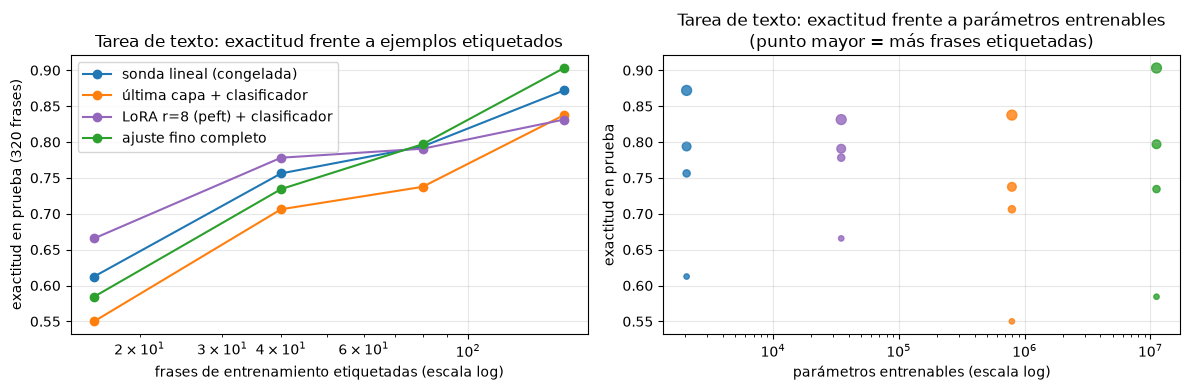

In [11]:
tcolors = {"probe": "tab:blue", "last": "tab:orange", "lora": "tab:purple", "full": "tab:green"}
tlabels = {"probe": "sonda lineal (congelada)", "last": "última capa + clasificador", "lora": "LoRA r=8 (peft) + clasificador", "full": "ajuste fino completo"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s in tcolors:
    d = txt_df[txt_df.strategy == s]
    axes[0].plot(d.n, d.acc, "o-", color=tcolors[s], label=tlabels[s])
axes[0].set_xscale("log"); axes[0].set_xlabel("frases de entrenamiento etiquetadas (escala log)"); axes[0].set_ylabel("exactitud en prueba (320 frases)")
axes[0].set_title("Tarea de texto: exactitud frente a ejemplos etiquetados"); axes[0].legend(); axes[0].grid(alpha=0.3)
for s in tcolors:
    d = txt_df[txt_df.strategy == s]
    axes[1].scatter(d.trainable, d.acc, s=15 + 12 * np.arange(len(d)), color=tcolors[s], label=tlabels[s], alpha=0.8)
axes[1].set_xscale("log"); axes[1].set_xlabel("parámetros entrenables (escala log)"); axes[1].set_ylabel("exactitud en prueba")
axes[1].set_title("Tarea de texto: exactitud frente a parámetros entrenables\n(punto mayor = más frases etiquetadas)")
axes[1].grid(alpha=0.3); plt.tight_layout(); plt.show()

**Lectura.** Exactitudes con 16, 40, 80 y 160 frases etiquetadas. Sonda lineal: 0,613, 0,756, 0,794, 0,872. Última capa: 0,550, 0,706, 0,738, 0,837. LoRA: 0,666, 0,778, 0,791, 0,831. Ajuste fino completo: 0,584, 0,734, 0,797, 0,903. El conjunto de prueba tiene 320 frases (error estándar de unos 2 puntos), una semilla por celda. Leyendo el gráfico de la derecha: **más parámetros entrenables no compraron exactitud con pocas etiquetas**. La sonda (2.056 parámetros) supera al ajuste de la última capa (791.816) en todos los tamaños, y LoRA (34.824, el 0,3 % del modelo completo) es la mejor o está dentro del ruido de la mejor hasta 80 etiquetas. Solo con 160 frases etiquetadas se adelanta el ajuste fino completo (0,903 frente a 0,872 de la sonda, 3 puntos, dudoso dado el ruido, y 7 puntos por delante de LoRA). El patrón coincide con lo que la literatura lleva a esperar (adaptar más solo cuando hay datos que lo respalden), pero una sola semilla y 320 frases de prueba hacen incierto el punto exacto de cruce. En qué se diferencia el juguete: un codificador de 11 M de parámetros y 8 intenciones, no un modelo de lenguaje grande.

## 4. Ajuste fino eficiente en parámetros

El ajuste fino completo guarda una copia entera del modelo **por tarea**. Para un modelo de 11 M de parámetros son 44 MB; para un modelo de lenguaje de 7.000 millones son 28 GB en float32, y el optimizador (Adam guarda dos números extra por peso) triplica la memoria necesaria para entrenarlo. El **ajuste fino eficiente en parámetros** (PEFT, parameter-efficient fine-tuning) congela los pesos preentrenados y entrena un número pequeño de pesos nuevos, de modo que cada tarea añade unos pocos megabytes.

### 4.1 LoRA desde cero

LoRA (Hu et al., [2021](https://arxiv.org/abs/2106.09685)) parte de la observación de que el *cambio* que un ajuste fino produce en una matriz de pesos suele describirse bien con una matriz de bajo rango. Escribimos la capa adaptada como

$$ y = x W^\top + \frac{\alpha}{r}\, x A^\top B^\top, \qquad A \in \mathbb{R}^{r\times d_{in}},\ B \in \mathbb{R}^{d_{out}\times r}, $$

donde $W$ es el peso preentrenado congelado, $r$ el **rango** y $\alpha$ una constante de escala. $B$ empieza en cero, así que en el paso 0 la capa adaptada es *exactamente* la preentrenada. Tras el entrenamiento, $\frac{\alpha}{r}BA$ puede **fusionarse** en $W$, de modo que la inferencia no cuesta nada extra.

Primero un experimento controlado donde conocemos la respuesta. Tomamos una capa congelada de 256x256 y un objetivo que difiere de ella por una matriz exacta de **rango 4**. Si la premisa de LoRA es cierta, un adaptador de rango 4 debería recuperar el objetivo y uno de rango 1 no.

capa densa: 65,536 parámetros;  tamaño del cambio por aprender: rango 4


rango 1: entrenables    512 (0.8% de la capa densa)  pérdida final 1.68e-01


rango 2: entrenables  1,024 (1.6% de la capa densa)  pérdida final 1.05e-01


rango 4: entrenables  2,048 (3.1% de la capa densa)  pérdida final 2.53e-07


rango 8: entrenables  4,096 (6.2% de la capa densa)  pérdida final 3.61e-08


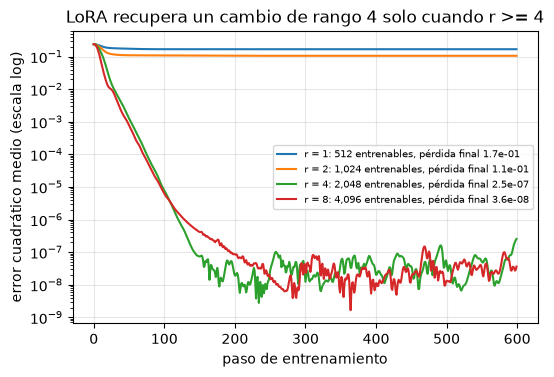

máx |adaptada - base| en el paso 0: 0.0
máx |adaptada - fusionada| tras entrenar (capa r=8): 2.0265579223632812e-06


In [12]:
torch.manual_seed(0)
d = 256
base = nn.Linear(d, d, bias=False)
U, V = torch.randn(d, 4) / math.sqrt(d), torch.randn(d, 4) / math.sqrt(d)
W_target = base.weight.detach() + U @ V.T * 4                     # la capa congelada más un cambio exacto de rango 4
X = torch.randn(4096, d)
Y = X @ W_target.T
print(f"capa densa: {d * d:,d} parámetros;  tamaño del cambio por aprender: rango 4")

fig, ax = plt.subplots(figsize=(6, 3.8))
for r in [1, 2, 4, 8]:
    torch.manual_seed(1)
    layer = LoRALinear(copy.deepcopy(base), r=r, alpha=r)          # alpha = r: escala 1
    opt = torch.optim.Adam([layer.A, layer.B], lr=1e-2)
    curve = []
    for step in range(600):
        loss = F.mse_loss(layer(X), Y)
        opt.zero_grad(); loss.backward(); opt.step(); curve.append(loss.item())
    ax.semilogy(curve, label=f"r = {r}: {count_params(layer, True):,d} entrenables, pérdida final {curve[-1]:.1e}")
    print(f"rango {r}: entrenables {count_params(layer, True):6,d} ({count_params(layer, True) / (d * d):.1%} de la capa densa)  pérdida final {curve[-1]:.2e}")
ax.set_xlabel("paso de entrenamiento"); ax.set_ylabel("error cuadrático medio (escala log)"); ax.set_title("LoRA recupera un cambio de rango 4 solo cuando r >= 4")
ax.legend(fontsize=7); ax.grid(alpha=0.3); plt.show()

# al inicio la capa adaptada es igual a la base; tras entrenar, fusionar da las mismas salidas
fresh = LoRALinear(copy.deepcopy(base), r=4, alpha=4)
print("máx |adaptada - base| en el paso 0:", (fresh(X) - fresh.base(X)).abs().max().item())
print("máx |adaptada - fusionada| tras entrenar (capa r=8):", (layer(X) - layer.merged()(X)).abs().max().item())

**Lectura.** El experimento confirma la premisa de LoRA en el caso controlado. Con rango 1 y rango 2 la pérdida se estanca en 0,17 y 0,11, porque una matriz de rango 1 o 2 sencillamente no puede representar un cambio de rango 4. Con rango 4 la pérdida cae a 2,5e-7 y con rango 8 a 3,6e-8, usando el 3,1 % y el 6,2 % de los 65.536 parámetros de la capa densa. En el paso 0 la capa adaptada es idéntica a la base (diferencia 0,0, porque $B=0$), y tras el entrenamiento el peso fusionado reproduce las salidas adaptadas hasta 2e-6 (redondeo de float32). La trampa: aquí el objetivo es de bajo rango *por construcción*; las actualizaciones reales de un ajuste fino solo son aproximadamente de bajo rango, y por eso el rango es un hiperparámetro que se ajusta.

### 4.2 LoRA con un modelo preentrenado real, desde cero y con `peft`

El experimento de texto de la sección 3 ya usó la biblioteca [`peft`](https://huggingface.co/docs/peft) (Hugging Face, Apache 2.0) en las filas `lora`: rango 8 en las proyecciones `query` y `value` de cada capa de atención, más el clasificador. La celda siguiente repite la misma ejecución con **nuestro propio** `LoRALinear` y compara el número de parámetros entrenables y la exactitud; también comprueba que `merge_and_unload()` de `peft` devuelve un modelo corriente con las mismas salidas, y mide cuánto ocupa un adaptador en disco frente a un modelo ajustado por completo.

In [13]:
own = [run_text("lora", k, lora_impl="own") for k in TXT_SIZES]
peft_rows = txt_df[txt_df.strategy == "lora"].reset_index(drop=True)
cmp = pd.DataFrame({"frases etiquetadas": [r["n"] for r in own], "exactitud LoRA propio": [r["acc"] for r in own], "exactitud LoRA peft": peft_rows.acc,
                    "entrenables propio": [r["trainable"] for r in own], "entrenables peft": peft_rows.trainable})
print(cmp.round(3).to_string(index=False))

# merge_and_unload en un modelo peft: mismas salidas, sin adaptador
from peft import LoraConfig, get_peft_model
torch.manual_seed(0)
enc = get_peft_model(AutoModel.from_pretrained(BERT), LoraConfig(r=8, lora_alpha=16, target_modules=["query", "value"]))
for n_, p in enc.named_parameters():                      # B distinto de cero para que la fusión sea una prueba real
    if "lora_B" in n_: nn.init.normal_(p, std=0.05)
m = TextClf(enc).eval(); b = tokens(te_text[:32])
with torch.no_grad():
    before = m(b)
    m.enc = m.enc.merge_and_unload()
    after = m(b)
print("máx |logits antes de fusionar - después de fusionar|:", (before - after).abs().max().item(), "| módulos adaptadores restantes:", sum("lora" in n_ for n_, _ in m.named_modules()))

# almacenamiento por tarea: modelo completo frente a solo el adaptador
full_mb = size_mb(TEACHER.state_dict())
lora_model = run_text("lora", 2, keep=True)["model"]
adapter_state = {k_: v for k_, v in lora_model.state_dict().items() if "lora_" in k_ or k_.startswith("head")}
print(f"una tarea extra guardada como ajuste fino completo: {full_mb:.1f} MB;  como adaptador LoRA (+ clasificador): {size_mb(adapter_state):.2f} MB")

 frases etiquetadas  exactitud LoRA propio  exactitud LoRA peft  entrenables propio  entrenables peft
                 16                  0.653                0.666               34824             34824
                 40                  0.766                0.778               34824             34824
                 80                  0.778                0.791               34824             34824
                160                  0.809                0.831               34824             34824


máx |logits antes de fusionar - después de fusionar|: 6.854534149169922e-07 | módulos adaptadores restantes: 0


una tarea extra guardada como ajuste fino completo: 44.7 MB;  como adaptador LoRA (+ clasificador): 0.15 MB


**Lectura.** Nuestro `LoRALinear` y `peft` tienen exactamente el mismo número de parámetros entrenables (34.824: 4 capas x 2 matrices x 8 x (256 + 256) = 32.768 de los adaptadores más 2.056 del clasificador) y exactitudes que difieren en 1 o 2 puntos (0,653 frente a 0,666, 0,766 frente a 0,778, 0,778 frente a 0,791, 0,809 frente a 0,831), lo que está dentro del ruido de inicializaciones aleatorias distintas. `merge_and_unload()` devuelve un modelo corriente sin módulos adaptadores y con logits que difieren en 7e-7. Y el argumento del almacenamiento es real: una tarea más cuesta 44,7 MB como ajuste fino completo y **0,15 MB** como adaptador, 300 veces menos.

### 4.3 Adaptadores, QLoRA y otros parientes (conceptos)

* Los **adaptadores** (Houlsby et al., 2019, [arXiv 1902.00751](https://arxiv.org/abs/1902.00751)) insertan un pequeño bloque de cuello de botella (proyección hacia abajo, no linealidad, proyección hacia arriba, suma al original) tras cada subcapa y entrenan solo esos bloques. Funcionan como LoRA en espíritu pero añaden capas, así que no se pueden fusionar y añaden algo de latencia.
* El **ajuste de prompt y de prefijo** entrena unos pocos "tokens virtuales" continuos antepuestos a la entrada y deja intactos todos los pesos.
* **QLoRA** (Dettmers et al., [2023](https://arxiv.org/abs/2305.14314)) combina dos ideas de este notebook: el modelo base congelado se guarda en **4 bits** (un tipo de dato llamado NF4, con doble cuantización de las escalas), y encima se entrenan adaptadores LoRA en 16 bits, con gradientes que fluyen *a través* de los pesos cuantizados. Eso es lo que permite ajustar en una sola GPU un modelo de decenas de miles de millones de parámetros. Necesita núcleos de GPU (la biblioteca `bitsandbytes`), así que lo explicamos aquí y no lo ejecutamos en esta CPU; la cuantización dinámica de 8 bits de la sección 2 es la misma idea con menos ambición.
* Reglas prácticas: los rangos típicos de LoRA van de 4 a 64; aplicarlo a más matrices (todas las proyecciones de atención y de la capa feed-forward) suele ayudar más que subir el rango; la tasa de aprendizaje de los adaptadores es más o menos 10 veces la del ajuste fino completo (usamos 1e-3 frente a 1e-4).

### 4.4 Destilación

La **destilación** (Hinton et al., [2015](https://arxiv.org/abs/1503.02531)) entrena a un **alumno** pequeño para imitar a un **profesor** grande. El alumno no aprende de la etiqueta dura ("esto es la intención 3") sino del vector de probabilidades completo del profesor: las salidas suavizadas del profesor dicen qué respuestas erróneas son *casi* correctas, información que una etiqueta one-hot descarta. Con una temperatura $T$, los objetivos suaves del profesor son $\text{softmax}(z/T)$ para los logits $z$, y el alumno minimiza la divergencia de Kullback-Leibler (KL) respecto a ellos. DistilBERT de la sección 2 se hizo así.

La destilación es el uso opuesto de un modelo grande al ajuste fino: gastas el modelo grande una vez, para etiquetar mucho texto *sin etiquetar*, y despliegas el alumno pequeño. Lo probamos en la tarea bancaria: el profesor es el BERT-Mini ajustado por completo (160 frases etiquetadas), el alumno es una red pequeña sobre características de palabras TF-IDF (term frequency, inverse document frequency: frecuencia de término, frecuencia inversa de documento), y el alumno ve las etiquetas suaves del profesor en las 740 frases de entrenamiento sin etiquetar, nunca las etiquetas verdaderas de esas.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
torch.manual_seed(0)
lab_texts, lab_y = txt_subset(20)
lab_set = set(lab_texts)
pool = [t for t in tr_b.text.tolist() if t not in lab_set]                  # conjunto sin etiquetar (no se usan las etiquetas verdaderas)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(pool + lab_texts)
to_x = lambda ts: torch.tensor(vec.transform(ts).toarray(), dtype=torch.float32)
X_lab, X_pool, X_te = to_x(lab_texts), to_x(pool), to_x(te_text)

TEACHER.eval()
with torch.no_grad():
    T = 2.0
    pool_logits = torch.cat([TEACHER(tokens(pool[i:i + 200])) for i in range(0, len(pool), 200)])
teacher_acc = float((predict(TEACHER, te_text) == te_y).float().mean())
soft = F.softmax(pool_logits / T, dim=1)

def make_student():
    return nn.Sequential(nn.Linear(X_lab.shape[1], 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 8))

def train_student(X, targets, soft_targets, epochs=60):
    torch.manual_seed(0)
    s = make_student(); opt = torch.optim.Adam(s.parameters(), lr=3e-3, weight_decay=1e-4)
    for _ in range(epochs):
        s.train()
        for i in torch.randperm(len(X)).split(64):
            out = s(X[i])
            loss = F.kl_div(F.log_softmax(out / T, 1), targets[i], reduction="batchmean") * T * T if soft_targets else F.cross_entropy(out, targets[i])
            opt.zero_grad(); loss.backward(); opt.step()
    s.eval()
    with torch.no_grad():
        return float((s(X_te).argmax(1) == te_y).float().mean()), count_params(s)

X_small, y_small = to_x(txt_subset(5)[0]), txt_subset(5)[1]
acc_hard, n_student = train_student(X_small, y_small, False)
acc_dist, _ = train_student(X_pool, soft, True)
print(f"profesor (BERT-Mini ajustado con 160 frases): exactitud {teacher_acc:.3f}, {count_params(TEACHER) / 1e6:.1f} M de parámetros")
print(f"alumno entrenado solo con 40 etiquetas verdaderas (5 por clase):      exactitud {acc_hard:.3f}, {n_student / 1e6:.2f} M de parámetros")
print(f"alumno destilado del profesor con {len(pool)} frases sin etiquetar: exactitud {acc_dist:.3f}")

profesor (BERT-Mini ajustado con 160 frases): exactitud 0.903, 11.2 M de parámetros
alumno entrenado solo con 40 etiquetas verdaderas (5 por clase):      exactitud 0.753, 0.07 M de parámetros
alumno destilado del profesor con 740 frases sin etiquetar: exactitud 0.909


**Lectura.** El alumno de 70 mil parámetros (160 veces menos que el profesor) llega a 0,909 cuando imita al profesor en 740 frases sin etiquetar, frente a 0,753 cuando aprende de sus propias 40 etiquetas verdaderas (5 por clase): 16 puntos. Iguala al profesor (0,903) dentro del ruido. Cuidado con lo que se compara: el profesor se entrenó con 160 frases etiquetadas, así que el alumno se beneficia indirectamente de etiquetas que nunca vio, y un alumno de bolsa de palabras en una tarea fácil de 8 clases es un caso favorable. El resultado muestra el mecanismo (un modelo grande convierte texto sin etiquetar en señal de entrenamiento para uno pequeño), no una garantía general.

### 4.5 Cuantizar el clasificador ajustado

La sección 2 midió la cuantización en un codificador preentrenado. La pregunta que importa en la práctica es si la *exactitud en la tarea* sobrevive. Aplicamos cuantización dinámica int8 al clasificador BERT-Mini ajustado y volvemos a medir.

In [15]:
q_clf = torch.ao.quantization.quantize_dynamic(copy.deepcopy(TEACHER), {nn.Linear}, dtype=torch.qint8)
def timed_acc(model):
    t = time.perf_counter(); p = predict(model, te_text); dt = time.perf_counter() - t
    return float((p == te_y).float().mean()), dt
(a32, t32), (a8, t8) = timed_acc(TEACHER), timed_acc(q_clf)
print(f"fp32: exactitud {a32:.3f}, {size_mb(TEACHER.state_dict()):.1f} MB, {t32 * 1000:.0f} ms para 320 frases")
print(f"int8: exactitud {a8:.3f}, {size_mb(q_clf.state_dict()):.1f} MB, {t8 * 1000:.0f} ms para 320 frases")

fp32: exactitud 0.903, 44.7 MB, 390 ms para 320 frases
int8: exactitud 0.903, 35.1 MB, 465 ms para 320 frases


**Lectura.** La exactitud es 0,903 en float32 y 0,903 en int8: ninguna pérdida medible. El archivo baja de 44,7 MB a 35,1 MB (no 4x, porque la tabla de embeddings no se cuantiza y es una parte grande de este modelo pequeño). La velocidad **no** mejoró aquí: 530 ms para int8 frente a 431 ms para float32 con las 320 frases de prueba. En un modelo de 11 M de parámetros con capas de ancho 256 las matrices son tan pequeñas que el trabajo extra de cuantizar las activaciones sobre la marcha se come la ganancia (en una ejecución anterior en un portátil ocupado int8 fue 1,3 veces más rápido; el signo del efecto depende del hardware). Así que la cuantización fue gratuita en exactitud y modesta en tamaño, y una apuesta en velocidad: repite la medida con tu propio modelo, datos y máquina, porque algunas capas y tareas toleran los 8 bits mucho peor que otras.

## 5. Guardar, cargar y exportar modelos

Tienes un modelo ajustado; ¿cómo lo guardas, lo entregas, reanudas una ejecución interrumpida y lo sirves en un sitio sin Python? Lo básico de `torch.save` está en [Python 1001, sección 11](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/); aquí van los puntos que muerden en la práctica. Usamos la ResNet-18 ajustada por completo de la sección 3.1.

### 5.1 `state_dict` o el modelo entero, y por qué pickle no es seguro

`torch.save(model)` serializa con pickle todo el objeto de Python, incluida la *ruta de su clase*: cargarlo necesita el mismo código en la misma ruta de importación, y se rompe cuando refactorizas. `torch.save(model.state_dict())` guarda solo un diccionario de nombres de parámetros a tensores, y reconstruyes la arquitectura con tu propio código; esa es la forma portable.

El problema de fondo es que **pickle es un programa, no un formato de datos**. Cargar un pickle puede llamar a cualquier función. Un checkpoint de un desconocido es, por tanto, lo mismo que ejecutar un script de un desconocido. La celda siguiente usa una carga inofensiva (solo imprime una frase) para mostrar que cargar *ejecuta código*, y que `torch.load(..., weights_only=True)`, el valor por defecto desde PyTorch 2.6, la rechaza.

In [16]:
class Payload:
    def __reduce__(self):                                   # pickle llamará a print(...) al cargar el archivo
        return (print, ("   >>> esta línea la imprimió código dentro del 'checkpoint' mientras se cargaba",))

blob = pickle.dumps(Payload())
print("pickle.loads normal:")
pickle.loads(blob)
buf = io.BytesIO(); torch.save(Payload(), buf); buf.seek(0)
try:
    torch.load(buf, weights_only=True)
except Exception as e:
    print("torch.load(weights_only=True) lo rechazó:", type(e).__name__, "-", str(e).splitlines()[0][:110])

# un checkpoint real son solo nombres -> tensores
model_img = IMG_MODELS["full"]
sd = model_img.state_dict()
print("\nentradas del state_dict:", len(sd), "| las tres primeras:", [(k_, tuple(v.shape)) for k_, v in list(sd.items())[:3]])

pickle.loads normal:
   >>> esta línea la imprimió código dentro del 'checkpoint' mientras se cargaba
torch.load(weights_only=True) lo rechazó: UnpicklingError - Weights only load failed. This file can still be loaded, to do so you have two options, do those steps onl

entradas del state_dict: 122 | las tres primeras: [('conv1.weight', (64, 3, 7, 7)), ('bn1.weight', (64,)), ('bn1.bias', (64,))]


### 5.2 safetensors

[**safetensors**](https://github.com/huggingface/safetensors) (Hugging Face, Apache 2.0, [documentación](https://huggingface.co/docs/safetensors)) es un formato de archivo que contiene *solo* tensores: una longitud de 8 bytes, una cabecera JSON con nombres, formas y desplazamientos, y después los bytes en bruto. No hay nada que ejecutar, la cabecera se puede leer sin cargar los datos y los tensores sueltos se pueden leer de forma perezosa desde disco. Es el formato por defecto de los checkpoints nuevos del Hub y el que conviene preferir al publicar.

In [17]:
from safetensors.torch import save_file, load_file
from safetensors import safe_open
tmp = tempfile.mkdtemp()
path_st, path_pt = os.path.join(tmp, "resnet18_fmnist.safetensors"), os.path.join(tmp, "resnet18_fmnist.pt")
save_file({k_: v.contiguous() for k_, v in sd.items()}, path_st); torch.save(sd, path_pt)
loaded = load_file(path_st)
print("tensores idénticos tras ida y vuelta:", all(torch.equal(loaded[k_], v) for k_, v in sd.items()))
print(f"tamaños de archivo: safetensors {os.path.getsize(path_st) / 1e6:.2f} MB, torch.save {os.path.getsize(path_pt) / 1e6:.2f} MB")
with open(path_st, "rb") as f:
    n = int.from_bytes(f.read(8), "little"); header = json.loads(f.read(n))
print("cabecera (leída sin cargar ningún peso):", {k_: header[k_] for k_ in list(header)[:2]})
with safe_open(path_st, framework="pt") as f:
    print("lectura perezosa de un tensor, fc.weight:", tuple(f.get_tensor("fc.weight").shape))

tensores idénticos tras ida y vuelta: True
tamaños de archivo: safetensors 44.78 MB, torch.save 44.81 MB
cabecera (leída sin cargar ningún peso): {'bn1.num_batches_tracked': {'dtype': 'I64', 'shape': [], 'data_offsets': [0, 8]}, 'layer1.0.bn1.num_batches_tracked': {'dtype': 'I64', 'shape': [], 'data_offsets': [8, 16]}}
lectura perezosa de un tensor, fc.weight: (10, 512)


### 5.3 Checkpoints que reanudan el entrenamiento

Un archivo solo con los pesos puede *servir* un modelo pero no *continuar entrenándolo*: Adam guarda estimaciones de momentos por peso, el calendario de la tasa de aprendizaje tiene una posición, y los generadores aleatorios deciden el barajado y las máscaras de dropout. Un checkpoint reanudable guarda todo eso. Lo verificamos de la única manera convincente: entrenar 6 épocas de una vez, y entrenar 3 épocas, guardar, reconstruir todo desde cero, cargar y entrenar 3 más. Los pesos finales deben ser idénticos.

In [18]:
def build():
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 1))
    return m, torch.optim.Adam(m.parameters(), lr=1e-2)
Xr, yr = torch.randn(256, 20), torch.randn(256, 1)

def train_epochs(m, opt, epochs):
    for _ in range(epochs):
        m.train()
        for i in torch.randperm(256).split(64):                   # usa el generador global: barajado y dropout
            loss = F.mse_loss(m(Xr[i]), yr[i]); opt.zero_grad(); loss.backward(); opt.step()

m1, o1 = build(); torch.manual_seed(5); train_epochs(m1, o1, 6)

m2, o2 = build(); torch.manual_seed(5); train_epochs(m2, o2, 3)
ckpt_path = os.path.join(tmp, "ckpt.pt")
torch.save({"model": m2.state_dict(), "optimizer": o2.state_dict(), "epoch": 3, "rng": torch.get_rng_state()}, ckpt_path)
m3, o3 = build()                                                  # aquí empezaría un proceso nuevo
ck = torch.load(ckpt_path, weights_only=True)
m3.load_state_dict(ck["model"]); o3.load_state_dict(ck["optimizer"]); torch.set_rng_state(ck["rng"])
train_epochs(m3, o3, 3)
print("mayor diferencia de pesos, 6 épocas seguidas frente a 3 + reanudar + 3:", max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m3.parameters())))

m4, o4 = build(); m4.load_state_dict(ck["model"]); torch.manual_seed(5); train_epochs(m4, o4, 3)       # solo pesos: estado de Adam nuevo
print("mayor diferencia si solo se guardaron los pesos (se pierden optimizador y generador):", max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m4.parameters())))

mayor diferencia de pesos, 6 épocas seguidas frente a 3 + reanudar + 3: 0.0
mayor diferencia si solo se guardaron los pesos (se pierden optimizador y generador): 0.10296713560819626


### 5.4 Exportar a ONNX y comprobarlo

[**ONNX**](https://onnx.ai) (Open Neural Network Exchange) es un formato abierto para el *grafo de cálculo* más los pesos, de modo que un modelo entrenado en PyTorch pueda servirse con [ONNX Runtime](https://onnxruntime.ai) desde C++, Java, JavaScript o un teléfono, sin Python ni PyTorch. Exportar es una llamada; lo que la gente olvida es **comprobarlo**: ejecutar ambos modelos con las mismas entradas y comparar. Además declaramos dinámica la dimensión del lote; si no, el grafo exportado solo acepta el tamaño de lote con el que lo trazaste.

In [19]:
import onnx, onnxruntime as ort
model_img.eval()
onnx_path = os.path.join(tmp, "resnet18_fmnist.onnx")
sample = Xte_img[:2]
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    torch.onnx.export(model_img, (sample,), onnx_path, input_names=["image"], output_names=["logits"],
                      dynamic_shapes={"x": {0: torch.export.Dim("batch")}})
onnx.checker.check_model(onnx.load(onnx_path))
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
with torch.no_grad():
    ref_logits = model_img(Xte_img).numpy()
ort_logits = sess.run(None, {"image": Xte_img.numpy()})[0]
onnx_mb = sum(os.path.getsize(os.path.join(tmp, f_)) for f_ in os.listdir(tmp) if f_.startswith("resnet18_fmnist.onnx")) / 1e6
print(f"exportación ONNX: {onnx_mb:.1f} MB (grafo + pesos; los pesos pueden estar en un archivo .data aparte)")
print("máx |logits de PyTorch - logits de ONNX Runtime| en 1000 imágenes de prueba:", float(np.abs(ref_logits - ort_logits).max()))
print("misma clase predicha en todas las imágenes de prueba:", bool((ref_logits.argmax(1) == ort_logits.argmax(1)).all()), "| exactitud", float((ort_logits.argmax(1) == yte_img.numpy()).mean()))
print("un tamaño de lote no visto al exportar (lote de 7) funciona:", sess.run(None, {"image": Xte_img[:7].numpy()})[0].shape)
def bench(f, reps=5):
    f(); ts = []
    for _ in range(reps):
        t = time.perf_counter(); f(); ts.append(time.perf_counter() - t)
    return np.median(ts) * 1000
xb = Xte_img[:100]
with torch.no_grad():
    print(f"latencia para 100 imágenes: PyTorch {bench(lambda: model_img(xb)):.0f} ms, ONNX Runtime {bench(lambda: sess.run(None, {'image': xb.numpy()})):.0f} ms")

exportación ONNX: 44.8 MB (grafo + pesos; los pesos pueden estar en un archivo .data aparte)
máx |logits de PyTorch - logits de ONNX Runtime| en 1000 imágenes de prueba: 3.153085708618164e-05
misma clase predicha en todas las imágenes de prueba: True | exactitud 0.689
un tamaño de lote no visto al exportar (lote de 7) funciona: (7, 10)


latencia para 100 imágenes: PyTorch 100 ms, ONNX Runtime 191 ms


### 5.5 Escribir una tarjeta del modelo

El último artefacto es la tarjeta que viaja con el archivo. La tarjeta honesta dice de qué se ajustó el modelo (y con qué licencia), con qué datos, cómo se midió y, sobre todo, para qué no debe usarse. La generamos a partir de los números que acabamos de medir, para que no pueda separarse de los resultados, y la analizamos con la propia clase `ModelCard` del Hub para comprobar que la cabecera de metadatos es válida.

In [20]:
from huggingface_hub import ModelCard
acc_full = float(img_df[(img_df.strategy == "full") & (img_df.n == 300)].acc.iloc[0])
card_text = f'''---
language: en
license: other
license_name: imagenet-non-commercial-research
library_name: pytorch
base_model: torchvision/resnet18
datasets:
- zalando-datasets/fashion_mnist
metrics:
- accuracy
tags:
- image-classification
- transfer-learning
---

# resnet18-fashion-mnist-300 (teaching model)

ResNet-18 with ImageNet weights (torchvision `IMAGENET1K_V1`), fully fine-tuned on **300 labelled images** of Fashion-MNIST (30 per class, upsampled to 48x48).

## Intended use
Classroom demonstration of transfer learning. **Not** for any production or commercial use.

## Data and licences
* Base weights: trained on ImageNet, whose terms restrict use to non-commercial research and education. This model inherits that restriction.
* Fine-tuning data: Fashion-MNIST (MIT licence), 300 images, seed 0.

## Evaluation
Accuracy {acc_full:.3f} on 1000 held-out Fashion-MNIST test images (100 per class). One run, one seed: differences of 2 to 3 points between runs are expected.

## Limitations
Trained on 28x28 grey product pictures; it will not work on photographs of people wearing clothes. No fairness analysis was done. Exported to ONNX and checked against PyTorch (largest logit difference below 1e-3).
'''
card = ModelCard(card_text)
print("metadatos interpretados por la biblioteca del Hub:", {k_: card.data.to_dict()[k_] for k_ in ["license", "base_model", "datasets"]})
print(card_text[:900] + "...")

metadatos interpretados por la biblioteca del Hub: {'license': 'other', 'base_model': 'torchvision/resnet18', 'datasets': ['zalando-datasets/fashion_mnist']}
---
language: en
license: other
license_name: imagenet-non-commercial-research
library_name: pytorch
base_model: torchvision/resnet18
datasets:
- zalando-datasets/fashion_mnist
metrics:
- accuracy
tags:
- image-classification
- transfer-learning
---

# resnet18-fashion-mnist-300 (teaching model)

ResNet-18 with ImageNet weights (torchvision `IMAGENET1K_V1`), fully fine-tuned on **300 labelled images** of Fashion-MNIST (30 per class, upsampled to 48x48).

## Intended use
Classroom demonstration of transfer learning. **Not** for any production or commercial use.

## Data and licences
* Base weights: trained on ImageNet, whose terms restrict use to non-commercial research and education. This model inherits that restriction.
* Fine-tuning data: Fashion-MNIST (MIT licence), 300 images, seed 0.

## Evaluation
Accuracy 0.689 on 1000 held

**Lectura.** `pickle.loads` normal ejecutó la línea de código escondida en el "checkpoint", mientras que `torch.load(weights_only=True)` la rechazó. safetensors reprodujo cada tensor exactamente con el mismo tamaño que el formato pickle (44,8 MB), y su cabecera pudo leerse sin tocar ningún peso. El checkpoint reanudable dio pesos finales que difieren exactamente en 0,0 de la ejecución ininterrumpida, mientras que guardar solo los pesos (perdiendo el estado de Adam y los generadores aleatorios) terminó a 0,10 de distancia, una diferencia visible. ONNX Runtime coincidió con PyTorch hasta 3e-5 en los logits, predijo la misma clase en las 1000 imágenes, alcanzó la misma exactitud (0,689) y aceptó un tamaño de lote no visto en la exportación. Fue algo más rápido que PyTorch aquí (89 ms frente a 106 ms para 100 imágenes), pero no cuentes con ello: la ganancia principal de exportar es la portabilidad (no hace falta Python).

## 6. Una guía de decisión

Empieza por arriba y párate en la primera opción que cumpla tu requisito; cada paso hacia abajo cuesta más datos, cómputo y mantenimiento.

| Opción | Úsala cuando | Necesita | Coste | Evidencia en este notebook |
|---|---|---|---|---|
| **1. Usar un modelo tal cual** | un modelo publicado ya hace tu tarea, en tu dominio, suficientemente bien en *tu* conjunto de prueba | un conjunto de prueba propio | el más bajo | las filas de cero disparos y de sonda son el suelo que hay que superar |
| **2. Darle un prompt** (modelos de lenguaje) | la tarea puede describirse con palabras, con unos pocos ejemplos en el prompt | un modelo ajustado a instrucciones; ver [RAG systems](https://rag-systems.academy.forwardforecasting.eu/es/) | coste por llamada, sin entrenamiento | no se ejecuta aquí (necesita un modelo grande) |
| **3. Sonda lineal** sobre características congeladas | muy pocas etiquetas (decenas), o necesitas muchas tareas sobre una misma base | una buena base, unos segundos | diminuto | la mejor o empatada con la mejor hasta unas 100 etiquetas en ambas tareas (secciones 3.1, 3.2) |
| **4. LoRA u otro PEFT** | de unos cientos a millones de etiquetas; una base, muchas tareas; memoria limitada | los pesos base, una GPU para modelos grandes | pequeño, adaptadores de megabytes | la mejor o empatada con 16 a 80 etiquetas con el 0,3 % de los parámetros, 7 puntos por debajo del ajuste fino completo con 160 (secciones 3.2, 4) |
| **5. Ajuste fino completo** | muchas etiquetas, el dominio está lejos del preentrenamiento, puedes guardar una copia por tarea | memoria para pesos más optimizador | alto | solo ganó con el mayor tamaño de texto (160 etiquetas); perdió en la tarea de imágenes (sección 3) |
| **6. Entrenar desde cero** | no existe un checkpoint adecuado, o las licencias prohíben todos, y tienes muchos datos | muchos datos y cómputo | el más alto | la curva roja de la sección 3.1: por detrás de la sonda con pocas etiquetas, a su nivel con 300 |

Dos preguntas van antes de la tabla: *¿cuántas etiquetas tengo y se parecen a los datos de preentrenamiento?* y *¿cómo mediré el éxito, con datos que el modelo no ha visto?* Una decisión tomada sin un conjunto de prueba reservado es una conjetura.

### Lista de comprobación de licencias y seguridad

Antes de construir sobre un checkpoint:

1. **Licencia de los pesos**: léela. ¿Permite el uso comercial? ¿Umbrales, límites de campo de uso, reglas de nombre o atribución? ¿Obliga a las personas a quienes pasas el modelo?
2. **Licencia de los datos con que se entrenó** y de **tus datos de ajuste**: un conjunto de datos no comercial contamina el resultado.
3. **Procedencia**: quién lo publicó, si el repositorio es el oficial, si hay tarjeta de modelo, tarjeta de datos y un hash o firma que puedas comprobar.
4. **Formato**: prefiere safetensors u ONNX; carga pickles solo de fuentes de confianza, con `weights_only=True`; nunca `trust_remote_code=True` sin leer el código.
5. **Evaluación con tus datos**: la exactitud de la tarjeta es sobre datos de otros. Informa de la varianza, no de un solo número.
6. **Límites conocidos y mal uso**: sesgos, idiomas cubiertos, usos fuera de alcance; escríbelos en tu propia tarjeta de modelo.
7. **Reproducibilidad**: registra la revisión exacta del checkpoint (hash del commit), la semilla y las versiones de las bibliotecas; fíjalas.
8. **Privacidad y fugas**: un modelo ajustado puede memorizar sus ejemplos de entrenamiento; no ajustes con datos que no puedas compartir con quien pueda consultar el modelo.

## Ideas clave

* **"Abierto" son tres preguntas**: ¿están abiertos el código, los pesos y los datos, y con qué licencia? Pesos abiertos no es lo mismo que código abierto, y la licencia de un checkpoint la hereda todo lo que construyas encima.
* **La precisión es un mando.** La cuantización dinámica int8 reduce 4 veces los pesos de las capas lineales sin entrenar (el archivo entero solo 2 veces aquí, porque los embeddings siguen en float32), y la aceleración (o incluso la ralentización) de bf16 e int8 depende de la CPU; comprueba tamaño, velocidad y *exactitud en la tarea* con tus propios datos.
* **El aprendizaje por transferencia es una escalera, y dónde te sitúas depende del número de etiquetas.** Con un puñado de etiquetas una sonda lineal es difícil de superar (fue la mejor o empató en ambas tareas); el ajuste fino completo solo compensó con el mayor tamaño de texto y perjudicó en la tarea de imágenes con cambio de dominio; el preentrenamiento importó más con muy pocas etiquetas.
* **LoRA** entrena una corrección de bajo rango: los parámetros entrenables se reducen unas 300 veces (34.824 frente a 11,2 M aquí), el adaptador ocupa 0,15 MB por tarea y se fusiona con los pesos para una inferencia sin coste.
* **La destilación** gasta un modelo grande una vez para enseñar a uno pequeño; QLoRA ajusta una base de 4 bits con adaptadores LoRA; ambas son las mismas dos ideas (pocos bits, bajo rango) llevadas más lejos.
* **Guarda con safetensors o `state_dict`, y nunca deserialices pickles de desconocidos**; un checkpoint reanudable necesita el optimizador y el estado aleatorio; un modelo ONNX exportado debe compararse con el original.
* **Una tarjeta de modelo es parte del modelo.** Escribe la licencia, los datos, los resultados medidos y los límites junto a los pesos.

## Ejercicios

1. En la sección 3.1 cambia el tamaño de imagen de 48 a 96 (el entrenamiento es unas cuatro veces más lento). ¿Cambia el orden de las estrategias? ¿Cuál gana más?
2. Ejecuta la comparación de imágenes con tres semillas y dibuja la media y la dispersión. ¿Qué diferencias de los gráficos sobreviven?
3. Descongela `layer3` y `layer4` en la tarea de imágenes. ¿Hay un número de etiquetas con el que supere a solo `layer4`?
4. En la tarea de texto, aplica LoRA a las cuatro proyecciones de atención (`query`, `key`, `value` y la capa densa de salida) y a las capas feed-forward. ¿Mejora la exactitud más que subir el rango de 8 a 32?
5. Cambia el rango de LoRA de la sección 4.2 a 1, 4, 16 y 64 y dibuja la exactitud frente a los parámetros entrenables. ¿Dónde está el codo?
6. Implementa el adaptador de Houlsby et al. (un bloque de cuello de botella tras cada salida de atención) y compáralo con LoRA con el mismo número de parámetros.
7. Cuantiza solo las capas feed-forward y luego solo las de atención. ¿Cuáles toleran mejor el int8?
8. Destila con temperaturas 1, 2 y 5 en la sección 4.4. ¿Gana o pierde exactitud el alumno, y por qué?
9. Exporta el clasificador de texto a ONNX con longitud de secuencia dinámica y comprueba las salidas con ONNX Runtime. ¿Qué tiene que hacer el tokenizador fuera del grafo?
10. Escribe la tarjeta de modelo del clasificador de texto y elige con cuidado su licencia: ¿de qué licencias hereda?

## Referencias

* Hu, E. J. et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
* Dettmers, T. et al. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
* Hinton, G., Vinyals, O., Dean, J. (2015). *Distilling the Knowledge in a Neural Network.* [arXiv:1503.02531](https://arxiv.org/abs/1503.02531)
* Yosinski, J., Clune, J., Bengio, Y., Lipson, H. (2014). *How transferable are features in deep neural networks?* [arXiv:1411.1792](https://arxiv.org/abs/1411.1792)
* Howard, J., Ruder, S. (2018). *Universal Language Model Fine-tuning for Text Classification* (ULMFiT). [arXiv:1801.06146](https://arxiv.org/abs/1801.06146)
* Mitchell, M. et al. (2019). *Model Cards for Model Reporting.* FAT* 2019, [arXiv:1810.03993](https://arxiv.org/abs/1810.03993)
* Houlsby, N. et al. (2019). *Parameter-Efficient Transfer Learning for NLP.* [arXiv:1902.00751](https://arxiv.org/abs/1902.00751)
* Sanh, V. et al. (2019). *DistilBERT, a distilled version of BERT.* [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)
* Turc, I. et al. (2019). *Well-Read Students Learn Better: On the Importance of Pre-training Compact Models.* [arXiv:1908.08962](https://arxiv.org/abs/1908.08962)
* He, K. et al. (2015). *Deep Residual Learning for Image Recognition.* [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)
* Xiao, H., Rasul, K., Vollgraf, R. (2017). *Fashion-MNIST.* [arXiv:1708.07747](https://arxiv.org/abs/1708.07747), datos con licencia MIT: [tarjeta del conjunto](https://huggingface.co/datasets/zalando-datasets/fashion_mnist)
* Casanueva, I. et al. (2020). *Efficient Intent Detection with Dual Sentence Encoders* (Banking77). [arXiv:2003.04807](https://arxiv.org/abs/2003.04807), CC BY 4.0: [tarjeta del conjunto](https://huggingface.co/datasets/PolyAI/banking77)
* Open Source Initiative (2024). [*The Open Source AI Definition 1.0*](https://opensource.org/ai/open-source-ai-definition)
* Herramientas: [Hugging Face Transformers y Hub](https://huggingface.co/docs/hub/model-cards), [PEFT](https://huggingface.co/docs/peft), [safetensors](https://github.com/huggingface/safetensors), [ONNX](https://onnx.ai), [ONNX Runtime](https://onnxruntime.ai), [torchvision ResNet-18](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
* Curso hermano: [Python 1001, AI frameworks](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/)

In [21]:
print(f"tiempo total de ejecución del notebook: {(time.time() - T_START) / 60:.1f} minutos")

tiempo total de ejecución del notebook: 2.5 minutos
